# Part 1 EDA → Part 2 Extraction: observational evidence audit

## Scope and safeguards

This separate notebook investigates **3,075 matched products**, using the existing linked Products, Images and unchanged gold Annotations tables. It compares their metadata against **the complete local Part 1 export**, with the existing broad 50K EDA extract shown separately. It reuses the saved seeded official-test prediction bundle: no model inference, training, dataset/image downloads, or modifications to earlier notebooks/models/annotations.

**Observed associations are not causal influence.** Structured product values are not visual ground truth. Missing metadata, absent gold annotations, unevaluated images, numerical parsing failures and wrong predictions are separate states. Official train/test membership stays unchanged. Test outcomes are not used to tune rules or model parameters.

The full gzip is streamed once for exact row-weighted coverage, label counts and fixed-bin distributions. Full-database P1/P25/P50/P75/P99 are **approximate** from a deterministic uniform reservoir of at most 20,000 finite values per nutrient; matched and 50K quantiles are exact. The complete export includes 56 duplicate barcode rows, unlike the unique matched-product cohort. All denominators and sampling caveats are retained.

In [19]:
from pathlib import Path
import sys
import json
import importlib
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / 'app.py').exists() and (ROOT / 'nutrition_extraction_solution/app.py').exists():
    ROOT = ROOT / 'nutrition_extraction_solution'
assert (ROOT / 'outputs/part1_part2_integration/provenance.json').is_file()
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
import scripts.eda_extraction_impact as impact
impact = importlib.reload(impact)
OUTPUT = ROOT / 'outputs/eda_extraction_impact'
provenance = json.loads((ROOT / 'outputs/part1_part2_integration/provenance.json').read_text(encoding='utf-8'))
print('Integration KPIs:', provenance['summary'])
print('Local complete gzip exists:', (ROOT / 'data/full_off/en.openfoodfacts.org.products.csv.gz').is_file())
print('Existing predicted test images:', json.loads((ROOT / 'data/part2_cache/layoutlm_bio/latest_test_bundle.json').read_text(encoding='utf-8'))['sample_count'])
print('No LayoutLM inference or dataset download will run.')

Integration KPIs: {'status': 'measured_complete_part1_snapshot', 'part1_product_rows': 4881991, 'part1_unique_barcodes': 4881935, 'part1_duplicate_rows': 56, 'part1_duplicate_barcode_groups': 56, 'part2_images': 3083, 'part2_unique_barcodes': 3083, 'part2_repeated_barcode_images': 0, 'overlapping_barcodes': 3075, 'overlap_percent_of_part2': 99.74051248783653, 'overlap_percent_of_part1': 0.06298731957717585, 'matched_images': 3075, 'unmatched_barcodes': 8, 'invalid_part2_barcode_images': 0}
Local complete gzip exists: True
Existing predicted test images: 20
No LayoutLM inference or dataset download will run.


## 1. Compute and cache the actual analysis

The first run scans the existing complete gzip in bounded chunks (no second download). Later runs reuse the source-size/mtime/version-validated background aggregates. Only the small integrated tables and cached predictions are loaded normally. Prediction linkage requires official split/source index, exact barcode, OCR words, boxes, original gold BIO labels and complete coverage to match. Unproven standalone smoke/upload caches are not pooled with the declared seeded evaluation cohort.

Outputs: full-snapshot distribution/metadata/label aggregates, matched image–nutrient coverage states, image–nutrient exact-span counts and parser diagnostics, validation flags, cross-source comparisons, error examples, five findings and provenance. All saved under `outputs/eda_extraction_impact/`.

In [20]:
FORCE_REBUILD_BACKGROUND = False
manifest, tables, findings = impact.run_analysis(ROOT, OUTPUT, force_background=FORCE_REBUILD_BACKGROUND)
assert manifest['matched_products'] == provenance['summary']['overlapping_barcodes']
assert manifest['model_inference_runs'] == 0
assert manifest['existing_notebooks_and_inputs_unchanged']
print('Matched products:', manifest['matched_products'])
print('Evaluated aligned cached test images:', manifest['evaluated_images'])
print('Prediction audit:', manifest['prediction_audit'])
print('Full background:', manifest['background'])
display(pd.DataFrame(findings))

Matched products: 3075
Evaluated aligned cached test images: 20
Prediction audit: {'bundle_sha256': '68adbc5d26f1b4c24652758349712aa1f96a99f1a006ab2732a7ca0134633473', 'bundle_path': 'C:\\Users\\SaniaJawaid\\Documents\\projects\\practice\\study\\nutrition_extraction_solution\\data\\part2_cache\\layoutlm_bio\\latest_test_bundle.json', 'bundle_images': 20, 'accepted_images': 20, 'rejected': [], 'selection': {'seed': 42, 'requested_images': 20, 'official_test_rows': 199, 'selected_source_indices': [6, 7, 8, 22, 23, 26, 28, 35, 55, 57, 59, 62, 70, 108, 139, 151, 163, 173, 188, 189], 'failures': []}, 'individual_cache_files_not_pooled': 30, 'policy': 'Only declared seeded official-test cohort pooled. Standalone smoke/upload/old-schema caches not pooled without equivalent provenance and alignment.', 'evaluated_matched_images': 20, 'matched_images': 3075, 'model_inference_runs': 0}
Full background: {'version': '1.1', 'source': {'path': 'C:\\Users\\SaniaJawaid\\Documents\\projects\\practice\\s

,eda_finding,impact,action,evidence_type,support
0,"Annotation selection: 3,075 matched products o...",Observed metadata-distribution difference demo...,Keep broad EDA and annotation-selected analysi...,observed descriptive association,"4,881,991 full rows; 3,075 matched products"
1,"1,313/26,115 image–nutrient pairs have a gold ...",Missing product metadata can coexist with anno...,Preserve gold annotations independently; label...,observed paired-source availability,"26,115 gold-positive image–nutrient pairs"
2,38/217 predicted BIO spans in the aligned cach...,High span tagging accuracy does not ensure com...,Report parsing support beside BIO PRF and keep...,observed cached-output diagnostic,20 evaluated images; 217 predicted spans
3,20/127 nutrient-identity/basis/unit-compatible...,Database records and extracted image values ar...,Prioritize discrepancy examples for image/vers...,observed cross-source discrepancy; causes unve...,127 comparable fields
4,Observed OCR-length strata: 61–120 words: F1 0...,Image text/layout characteristics coincide wit...,"Maintain the frozen official-test cohort, show...",observed sample limitation; driver claims expl...,20 official-test images; zero new inference runs


## 2. Representativeness: distributions, countries, categories and completeness

Read the cached full-row counts, exact fixed-bin distributions and approximate full quantiles alongside exact matched/50K quantiles. Each source's denominator is displayed. The full database is row-weighted; the matched cohort is unique-product weighted. Multi-label category/country fractions can sum above one. The 50K prefix is not representative ground truth and is not substituted for the full database.

Interpretation: distribution/completeness differences describe annotation-selection bias and likely review needs; they do not prove that selecting those products caused the model's errors.

,dataset,nutrient,source_field,unit,products_or_rows,numeric_count,coverage,source_field_available,p01,q25,median,q75,p99,quantile_sample_size,quantiles_approximate,negative_count,upper_review_count,min,max
0,Full Part 1 snapshot (all rows),energy_kcal,energy-kcal_100g,kcal,4881991,3510807,0.719134,True,0.0,106.000000,2.500000e+02,3.930000e+02,846.040000,20000,True,1,16553,-113.860000,6.863447e+18
1,Full Part 1 snapshot (all rows),energy_kj,energy-kj_100g,kj,4881991,2570089,0.526443,True,0.0,468.000000,1.067826e+03,1.656500e+03,3381.802000,20000,True,18,1429,-2333.333333,2.854033e+19
2,Full Part 1 snapshot (all rows),fat,fat_100g,g,4881991,3478814,0.712581,True,0.0,1.000000,7.141429e+00,2.058824e+01,91.600000,20000,True,3,6534,-1.433973,8.565352e+47
3,Full Part 1 snapshot (all rows),saturated_fat,saturated-fat_100g,g,4881991,3197314,0.654920,True,0.0,0.119412,2.000000e+00,7.000000e+00,29.631700,20000,True,4,1154,-3.992188,2.001005e+15
4,Full Part 1 snapshot (all rows),carbohydrates,carbohydrates_100g,g,4881991,3480608,0.712948,True,0.0,3.567500,1.500000e+01,5.150000e+01,96.603000,20000,True,1,14804,-1.000000,1.540774e+18
5,Full Part 1 snapshot (all rows),sugars,sugars_100g,g,4881991,3272917,0.670406,True,0.0,0.666917,3.570000e+00,1.616162e+01,82.000000,20000,True,0,6672,0.000000,1.174717e+33
6,Full Part 1 snapshot (all rows),fiber,fiber_100g,g,4881991,1877092,0.384493,True,0.0,0.000000,1.600000e+00,3.846154e+00,27.502778,20000,True,108,533,-44.700000,1.000000e+07
7,Full Part 1 snapshot (all rows),proteins,proteins_100g,g,4881991,3484294,0.713703,True,0.0,1.800000,6.666667e+00,1.400000e+01,72.901000,20000,True,6,2048,-12.600000,1.380693e+17
8,Full Part 1 snapshot (all rows),salt,salt_100g,g,4881991,3053398,0.625441,True,0.0,0.090000,5.600000e-01,1.400000e+00,15.912647,20000,True,3,2678,-0.454363,2.195208e+08
9,Full Part 1 snapshot (all rows),sodium,sodium_100g,g,4881991,3053403,0.625442,True,0.0,0.032609,2.219524e-01,5.400000e-01,6.200900,20000,True,3,1780,-0.182791,8.780831e+07


,dataset,field,count,denominator,fraction
0,Full Part 1 snapshot (all rows),product_name,4537302,4881991,0.929396
1,Full Part 1 snapshot (all rows),brands,3128109,4881991,0.640745
2,Full Part 1 snapshot (all rows),categories,1148475,4881991,0.235247
3,Full Part 1 snapshot (all rows),countries,3415687,4881991,0.699650
4,Full Part 1 snapshot (all rows),serving_size,1587510,4881991,0.325177
5,Full Part 1 snapshot (all rows),image_nutrition_url,2353300,4881991,0.482037
6,Broad 50K EDA sample,product_name,49739,50000,0.994780
7,Broad 50K EDA sample,brands,49341,50000,0.986820
8,Broad 50K EDA sample,categories,14574,50000,0.291480
9,Broad 50K EDA sample,countries,42799,50000,0.855980


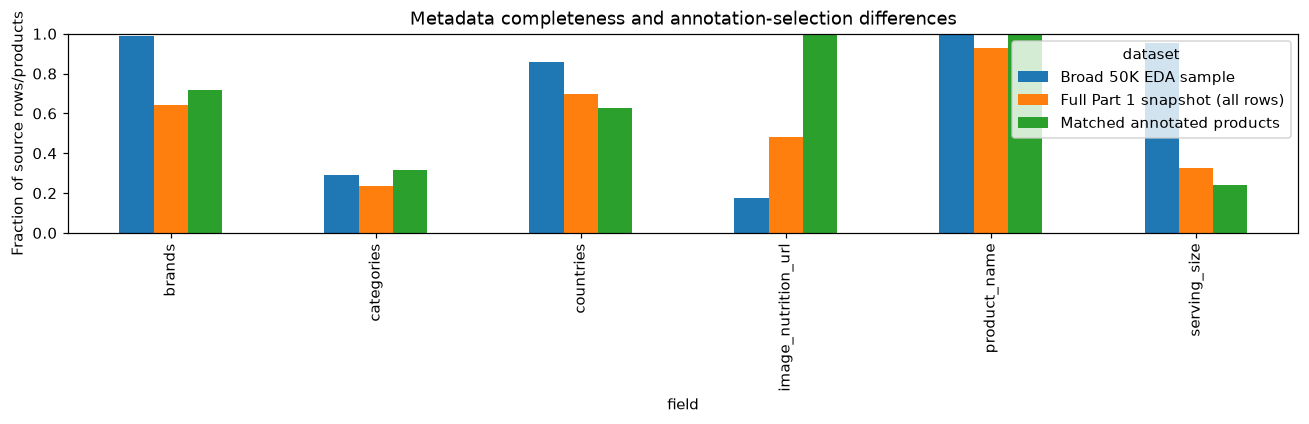

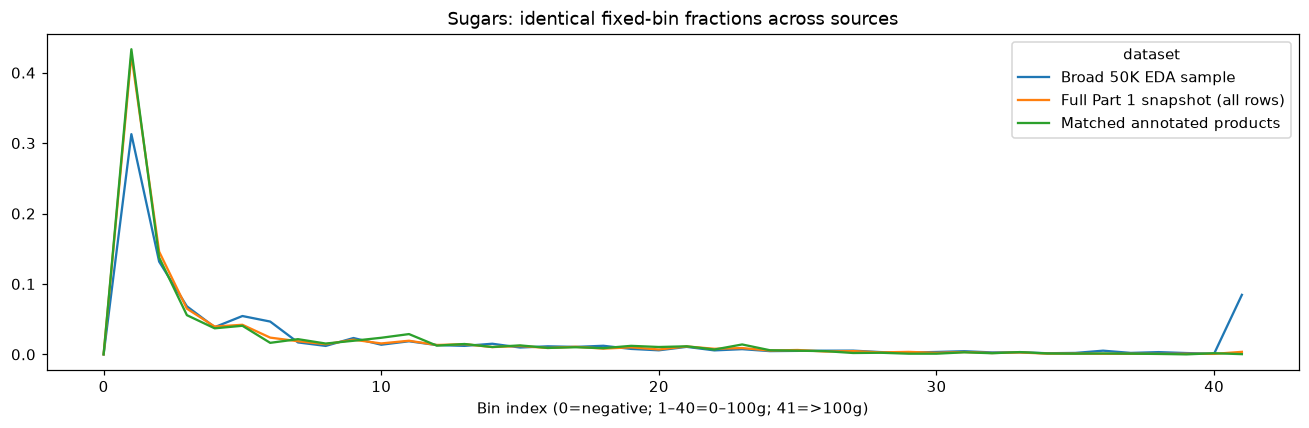

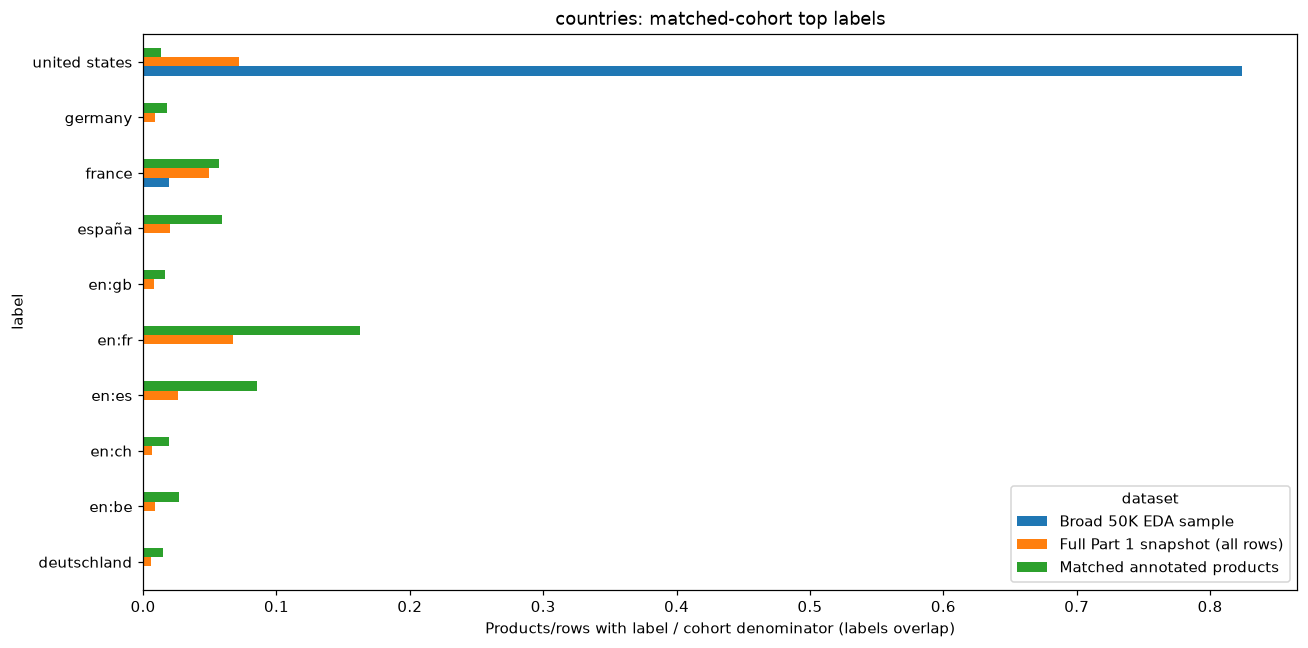

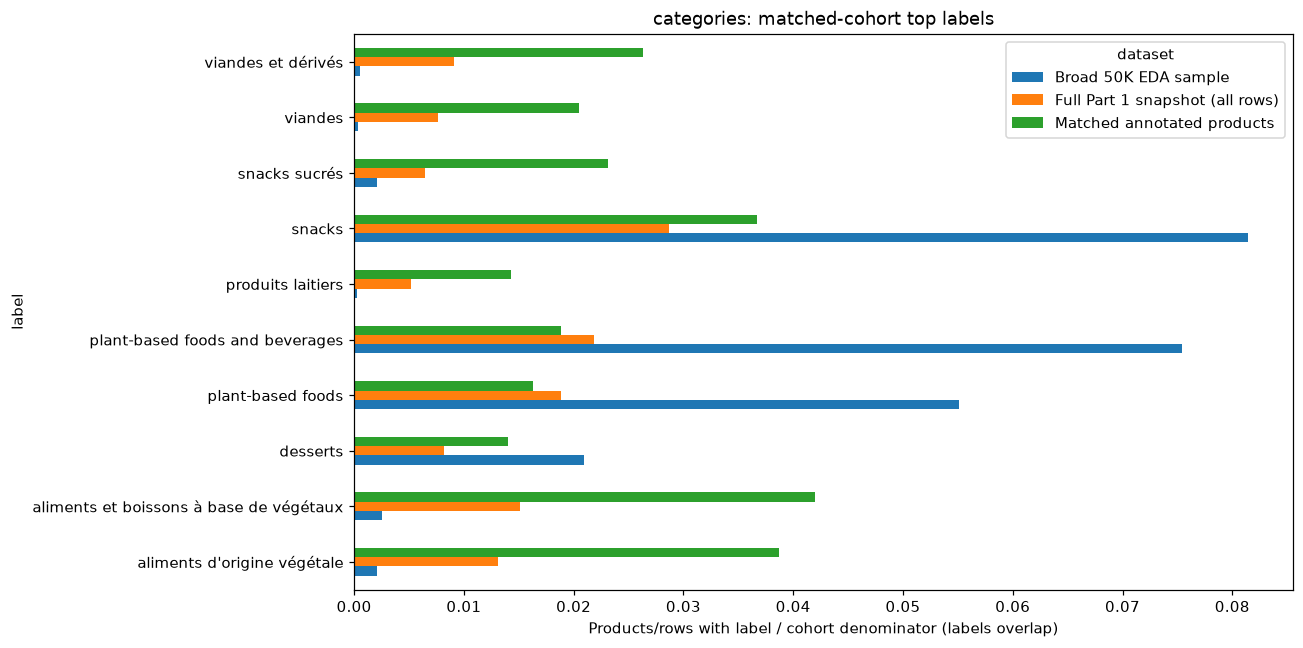

Full quantile method: seed42 bounded uniform reservoir, at most 20,000 finite observations per nutrient; full quantiles approximate, counts/histograms exact


In [11]:
import matplotlib
matplotlib.use('Agg', force=True)  # Noninteractive rendering: never waits for a GUI/browser.
import matplotlib.pyplot as plt
from IPython.display import Image as DisplayImage

FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(exist_ok=True)
def save_plot(filename):
    path = FIGURES / filename
    plt.tight_layout()
    plt.savefig(path, dpi=110, bbox_inches='tight')
    plt.close('all')
    display(DisplayImage(filename=str(path)))

representation = pd.read_parquet(OUTPUT / 'representativeness.parquet')
metadata = pd.read_parquet(OUTPUT / 'metadata_coverage.parquet')
label_distributions = pd.read_parquet(OUTPUT / 'label_distributions.parquet')
bins = pd.read_parquet(OUTPUT / 'distribution_bins.parquet')
display(representation.head(17))
display(metadata)
metadata.pivot(index='field', columns='dataset', values='fraction').plot.bar(figsize=(12, 4), ylim=(0, 1), title='Metadata completeness and annotation-selection differences')
plt.ylabel('Fraction of source rows/products')
save_plot('metadata_completeness.png')
bins.loc[bins['nutrient'].eq('sugars')].pivot(index='bin_index', columns='dataset', values='fraction').plot(figsize=(12, 4), title='Sugars: identical fixed-bin fractions across sources')
plt.xlabel('Bin index (0=negative; 1–40=0–100g; 41=>100g)')
save_plot('sugars_distributions.png')
for dimension in ['countries', 'categories']:
    selected = label_distributions.loc[label_distributions['dimension'].eq(dimension)]
    top = selected.loc[selected['dataset'].eq('Matched annotated products')].nlargest(10, 'count')['label']
    selected.loc[selected['label'].isin(top)].pivot(index='label', columns='dataset', values='fraction').fillna(0).plot.barh(figsize=(12, 6), title=f'{dimension}: matched-cohort top labels')
    plt.xlabel('Products/rows with label / cohort denominator (labels overlap)')
    save_plot(f'{dimension}_representation.png')
print('Full quantile method:', manifest['background']['quantile_method'])

## 3. Nutrient coverage and unit-aware anomaly review

Coverage is image–nutrient presence, not numerical correctness. All-matched metadata/gold use one denominator; the evaluated-cohort columns share the smaller evaluated-image denominator. No predicted span on an unevaluated image is recorded as **not evaluated**, not failure. A nutrient with no gold span is **not annotated**, not proven absent.

Review flags retain raw values: negatives; mapped mass above 100 g/100 g; energy above 1000 kcal or 4200 kJ/100 g. Bounds are nutrient/unit/basis-specific and are never applied to servings without a serving mass. Source `_100g` conventions may still hide beverage density/per-volume ambiguity. IQR and P1/P99 tails are statistical review prompts, not error labels. Thresholds never alter gold or model parameters.

,nutrient,source,images_with_value,denominator,coverage,state
0,added_sugars,Structured numeric product records,1206.0,3075,0.392195,measured
1,added_sugars,Gold BIO annotation present,68.0,3075,0.022114,measured
2,added_sugars,Structured numeric (evaluated cohort),12.0,20,0.600000,measured
3,added_sugars,Gold BIO (evaluated cohort),1.0,20,0.050000,measured
4,added_sugars,Model BIO prediction (evaluated only),1.0,20,0.050000,measured
...,...,...,...,...,...,...
85,vitamin_d,Structured numeric product records,450.0,3075,0.146341,measured
86,vitamin_d,Gold BIO annotation present,55.0,3075,0.017886,measured
87,vitamin_d,Structured numeric (evaluated cohort),5.0,20,0.250000,measured
88,vitamin_d,Gold BIO (evaluated cohort),0.0,20,0.000000,measured


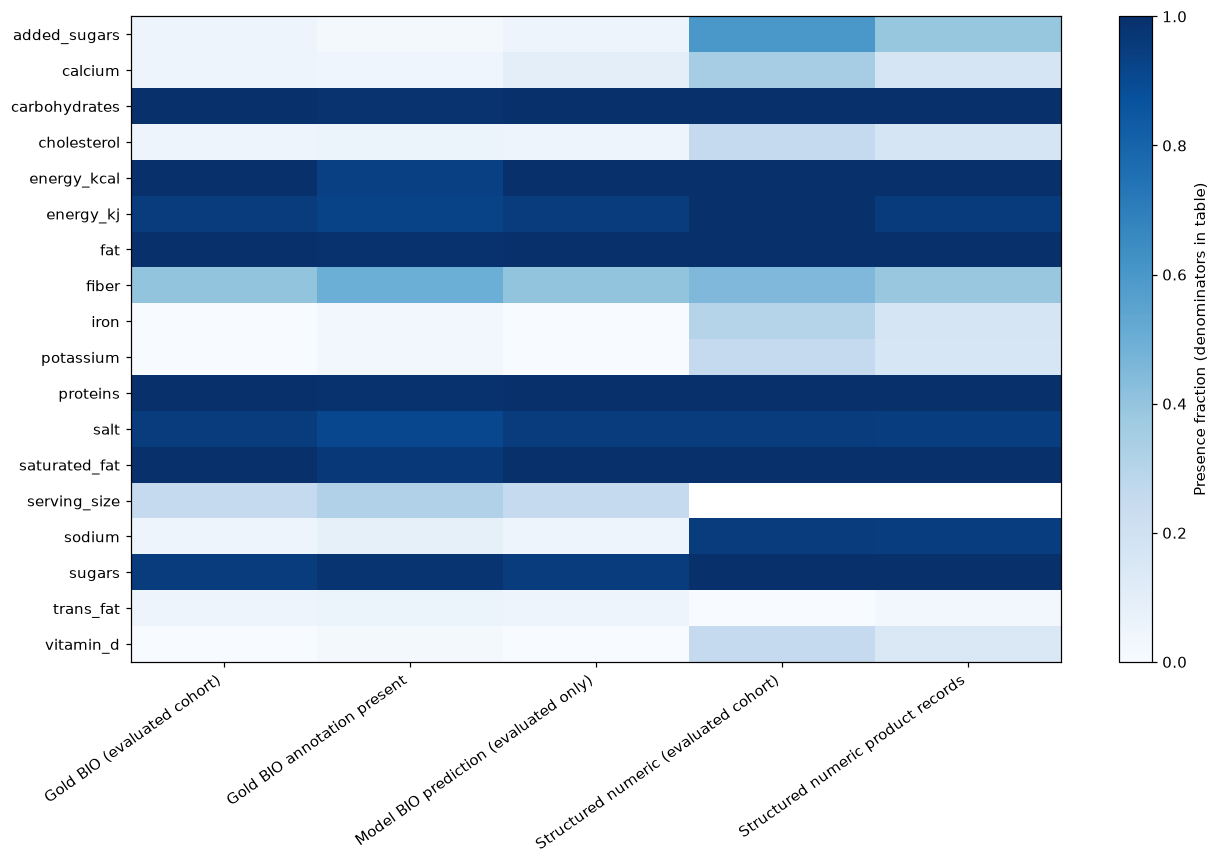

,nutrient,numeric_products,p01,q25,median,q75,p99,iqr_lower,iqr_upper,thresholds_scope
0,added_sugars,1206,0.000000,0.000000e+00,1.185024e-02,1.066500e+01,78.107639,-1.599750e+01,2.666250e+01,matched product metadata descriptive only; no ...
1,calcium,527,0.000000,1.232695e-02,3.100000e-02,1.034264e-01,0.712920,-1.243222e-01,2.400756e-01,matched product metadata descriptive only; no ...
2,carbohydrates,3067,0.000000,3.200000e+00,1.500000e+01,5.080000e+01,90.170000,-6.820000e+01,1.222000e+02,matched product metadata descriptive only; no ...
3,cholesterol,508,0.000000,0.000000e+00,4.387025e-04,2.248507e-02,0.216982,-3.372760e-02,5.621267e-02,matched product metadata descriptive only; no ...
4,energy_kcal,3063,6.000000,1.210000e+02,2.590000e+02,4.050000e+02,805.360000,-3.050000e+02,8.310000e+02,matched product metadata descriptive only; no ...
5,energy_kj,2938,37.965689,5.105000e+02,1.077800e+03,1.685850e+03,3026.128000,-1.252525e+03,3.448875e+03,matched product metadata descriptive only; no ...
6,fat,3068,0.000000,1.691667e+00,8.500000e+00,2.292500e+01,82.000000,-3.015833e+01,5.477500e+01,matched product metadata descriptive only; no ...
7,fiber,1201,0.000000,4.000000e-01,1.600000e+00,3.817110e+00,22.000000,-4.725665e+00,8.942775e+00,matched product metadata descriptive only; no ...
8,iron,528,0.000000,1.963419e-04,7.929511e-04,2.004248e-03,0.027631,-2.515517e-03,4.716107e-03,matched product metadata descriptive only; no ...
9,potassium,482,0.000000,1.424942e-01,2.048468e-01,3.373165e-01,1.672422,-1.497393e-01,6.295500e-01,matched product metadata descriptive only; no ...


,nutrient,numeric_products,physical_review,iqr_flags,p01_p99_tail_flags
0,added_sugars,1206,1,153,13
1,calcium,527,1,30,7
2,carbohydrates,3067,3,3,31
3,cholesterol,508,0,74,6
4,energy_kcal,3063,6,15,60
5,energy_kj,2938,0,4,60
6,fat,3068,2,84,29
7,fiber,1201,0,86,12
8,iron,528,1,52,6
9,potassium,482,1,32,5


,image_key,barcode,split,country,category,width,height,token_count,aspect_ratio,metadata_fields_present,...,nutrient,source_field,value,unit,basis,rules,physical_review,rule_scope,iqr_outlier,tail_p01_p99
2338,train:223,3760208140119,train,France,None,1698,1200,26,1.415000,2,...,energy_kcal,energy-kcal_100g,1.255000e+03,kcal,per_100g,energy_above_1000kcal_per_100g_review,True,source _100g convention; unit/nutrient-specifi...,True,True
4211,train:402,0011110004925,train,United States,null,712,291,90,2.446735,4,...,fat,fat_100g,1.300000e+02,g,per_100g,mass_above_100g_per_100g_review,True,source _100g convention; unit/nutrient-specifi...,True,True
5713,train:544,0013256220412,train,None,None,611,557,116,1.096948,1,...,iron,iron_100g,1.000000e+03,g,per_100g,mass_above_100g_per_100g_review,True,source _100g convention; unit/nutrient-specifi...,True,True
5714,train:544,0013256220412,train,None,None,611,557,116,1.096948,1,...,potassium,potassium_100g,6.000000e+02,g,per_100g,mass_above_100g_per_100g_review,True,source _100g convention; unit/nutrient-specifi...,True,True
7937,train:761,0055742347807,train,None,None,574,668,40,0.859281,3,...,sodium,sodium_100g,6.000000e+02,g,per_100g,mass_above_100g_per_100g_review,True,source _100g convention; unit/nutrient-specifi...,True,True
7942,train:761,0055742347807,train,None,None,574,668,40,0.859281,3,...,salt,salt_100g,1.500000e+03,g,per_100g,mass_above_100g_per_100g_review,True,source _100g convention; unit/nutrient-specifi...,True,True
8302,train:793,0010749008274,train,United States,null,705,944,68,0.746822,4,...,carbohydrates,carbohydrates_100g,1.490000e+02,g,per_100g,mass_above_100g_per_100g_review,True,source _100g convention; unit/nutrient-specifi...,True,True
11488,train:1103,01212901,train,None,None,931,830,83,1.121687,3,...,added_sugars,added-sugars_100g,1.167513e+03,g,per_100g,mass_above_100g_per_100g_review,True,source _100g convention; unit/nutrient-specifi...,True,True
13829,train:1328,0014100074816,train,None,None,901,1200,200,0.750833,3,...,energy_kcal,energy-kcal_100g,1.625000e+03,kcal,per_100g,energy_above_1000kcal_per_100g_review,True,source _100g convention; unit/nutrient-specifi...,True,True
13892,train:1333,7141047200749,train,None,None,881,1200,32,0.734167,2,...,calcium,calcium_100g,-2.485864e-02,g,per_100g,negative_quantity,True,source _100g convention; unit/nutrient-specifi...,False,True


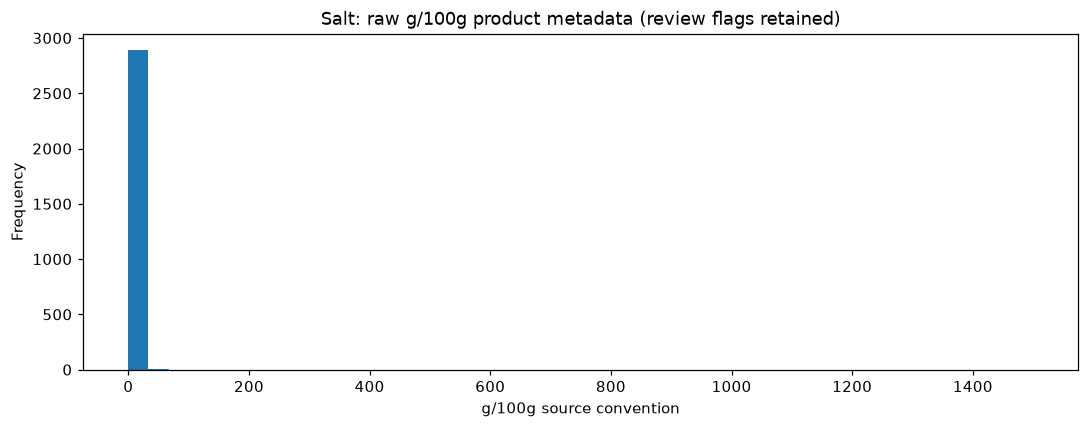

No anomalous values were corrected or substituted into model inputs.


In [21]:
coverage = impact.coverage_summary(tables['coverage_rows'])
display(coverage)
heatmap = coverage.pivot(index='nutrient', columns='source', values='coverage')
fig, axis = plt.subplots(figsize=(12, 8))
image = axis.imshow(heatmap.to_numpy(dtype=float), vmin=0, vmax=1, aspect='auto', cmap='Blues')
axis.set_yticks(range(len(heatmap)), heatmap.index)
axis.set_xticks(range(len(heatmap.columns)), heatmap.columns, rotation=35, ha='right')
fig.colorbar(image, ax=axis, label='Presence fraction (denominators in table)')
save_plot('nutrient_coverage_heatmap.png')
anomaly = tables['anomaly_rows']
display(tables['anomaly_thresholds'])
flags = anomaly.groupby('nutrient').agg(numeric_products=('value','size'), physical_review=('physical_review','sum'), iqr_flags=('iqr_outlier','sum'), p01_p99_tail_flags=('tail_p01_p99','sum')).reset_index()
display(flags)
display(anomaly.loc[anomaly['physical_review']].head(30))
anomaly.loc[anomaly['nutrient'].eq('salt'), 'value'].plot.hist(bins=45, figsize=(10, 4), title='Salt: raw g/100g product metadata (review flags retained)')
plt.xlabel('g/100g source convention')
save_plot('salt_anomalies.png')
print('No anomalous values were corrected or substituted into model inputs.')

## 4. Cached extraction performance and potential error drivers

Exact-span micro precision/recall/F1 preserve the fine nutrient and basis label. Numerical parsing success is separately defined as parseable predicted spans / predicted spans, not correct values. Each group shows distinct image count, entity-contributing image count and gold/predicted support. Metrics are suppressed below **5 entity-contributing images or 5 gold spans**; parsing also needs 5 predicted spans.

Group by nutrient, category, country, OCR word count, pixel width, aspect ratio and metadata availability. Country/category membership is multi-label and overlapping, so group rows cannot be added as independent samples. Image dimensions are not blur scores. Errors are on the dataset-supplied OCR, not a measured EasyOCR transcription benchmark. Train-only filters have no cached predictions and therefore no model score.

Overall cached count-based performance: {'tp': 201, 'pred_spans': 217, 'gold_spans': 211, 'parsed_predictions': 179, 'pred_entities': 217, 'token_errors': 22, 'token_support': 1551, 'images': 20, 'entity_contributing_images': 20, 'sufficient_support': True, 'precision': 0.9262672811059908, 'recall': 0.95260663507109, 'f1': 0.939252336448598, 'parsing_success': 0.8248847926267281, 'note': 'Metrics suppressed below 5 distinct images or 5 gold spans; parsing requires 5 predicted entities. All counts remain visible.'}
Grouping: nutrient


,dimension,group,tp,pred_spans,gold_spans,parsed_predictions,pred_entities,token_errors,token_support,images,entity_contributing_images,sufficient_support,precision,recall,f1,parsing_success,note
0,nutrient,added_sugars,0,2,1,1,2,1,1551,20,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
1,nutrient,calcium,2,3,2,2,3,2,1551,20,2,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
2,nutrient,carbohydrates,23,26,24,20,26,7,1551,20,20,True,0.884615,0.958333,0.920000,0.769231,Metrics suppressed below 5 distinct images or ...
3,nutrient,cholesterol,1,1,1,1,1,0,1551,20,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
4,nutrient,energy_kcal,24,25,24,22,25,2,1551,20,20,True,0.960000,1.000000,0.979592,0.880000,Metrics suppressed below 5 distinct images or ...
5,nutrient,energy_kj,23,23,23,20,23,0,1551,20,19,True,1.000000,1.000000,1.000000,0.869565,Metrics suppressed below 5 distinct images or ...
6,nutrient,fat,22,23,24,21,23,6,1551,20,20,True,0.956522,0.916667,0.936170,0.913043,Metrics suppressed below 5 distinct images or ...
7,nutrient,fiber,9,11,11,9,11,2,1551,20,8,True,0.818182,0.818182,0.818182,0.818182,Metrics suppressed below 5 distinct images or ...
8,nutrient,proteins,23,24,24,19,24,3,1551,20,20,True,0.958333,0.958333,0.958333,0.791667,Metrics suppressed below 5 distinct images or ...
9,nutrient,salt,23,24,23,21,24,2,1551,20,19,True,0.958333,1.000000,0.978723,0.875000,Metrics suppressed below 5 distinct images or ...


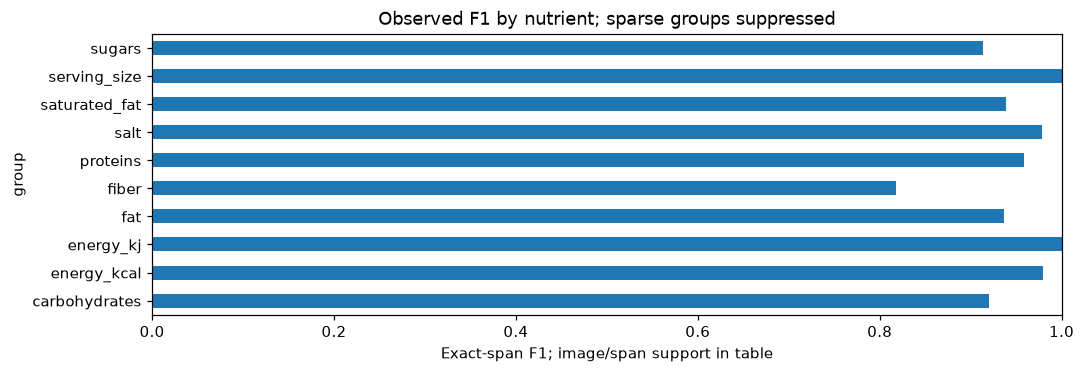

Grouping: category


,dimension,group,tp,pred_spans,gold_spans,parsed_predictions,pred_entities,token_errors,token_support,images,entity_contributing_images,sufficient_support,precision,recall,f1,parsing_success,note
0,category,(metadata missing),166,182,176,148,182,22,1303,17,17,True,0.912088,0.943182,0.927374,0.813187,Metrics suppressed below 5 distinct images or ...
1,category,alkoholfreie getränke,8,8,8,8,8,0,70,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
2,category,carnes,8,8,8,8,8,0,45,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
3,category,embutidos,8,8,8,8,8,0,45,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
4,category,en:cured-ham,8,8,8,8,8,0,45,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
5,category,fromages,19,19,19,15,19,0,133,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
6,category,fromages de vache,19,19,19,15,19,0,133,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
7,category,fromages des pays-bas,19,19,19,15,19,0,133,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
8,category,fromages à pâte pressée non cuite,19,19,19,15,19,0,133,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
9,category,fruchtgetränke,8,8,8,8,8,0,70,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...


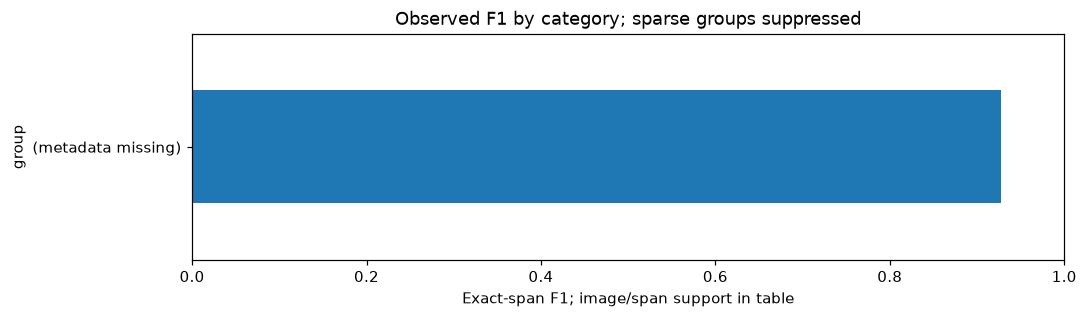

Grouping: country


,dimension,group,tp,pred_spans,gold_spans,parsed_predictions,pred_entities,token_errors,token_support,images,entity_contributing_images,sufficient_support,precision,recall,f1,parsing_success,note
0,country,(metadata missing),120,128,124,102,128,9,964,12,12,True,0.9375,0.967742,0.952381,0.796875,Metrics suppressed below 5 distinct images or ...
1,country,deutschland,8,8,8,8,8,0,70,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
2,country,en:be,19,19,19,15,19,0,133,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
3,country,en:es,35,35,35,33,35,0,196,3,3,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
4,country,en:fr,8,8,8,8,8,0,33,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
5,country,en:germany,8,8,8,8,8,0,70,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
6,country,españa,8,8,8,8,8,0,45,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
7,country,france,3,11,9,5,11,13,110,1,1,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...


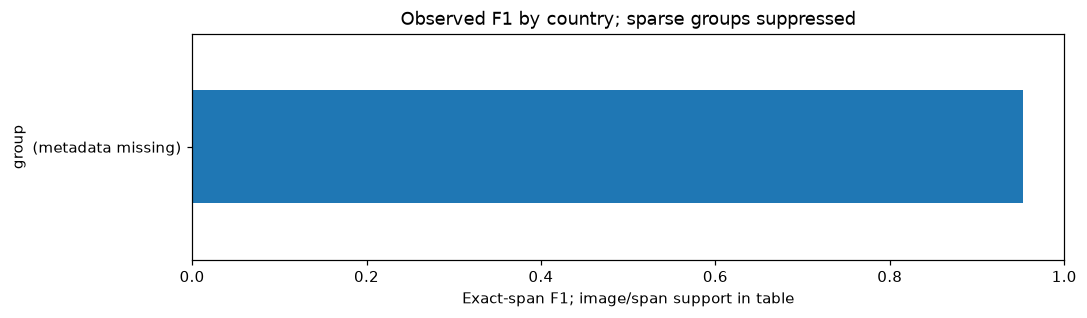

Grouping: token_count


,dimension,group,tp,pred_spans,gold_spans,parsed_predictions,pred_entities,token_errors,token_support,images,entity_contributing_images,sufficient_support,precision,recall,f1,parsing_success,note
0,token_count,61–120,92,105,100,84,105,20,789,9,9,True,0.876190,0.92000,0.897561,0.800000,Metrics suppressed below 5 distinct images or ...
1,token_count,>120,47,47,47,42,47,0,431,3,3,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
2,token_count,≤60,62,65,64,53,65,2,331,8,8,True,0.953846,0.96875,0.961240,0.815385,Metrics suppressed below 5 distinct images or ...


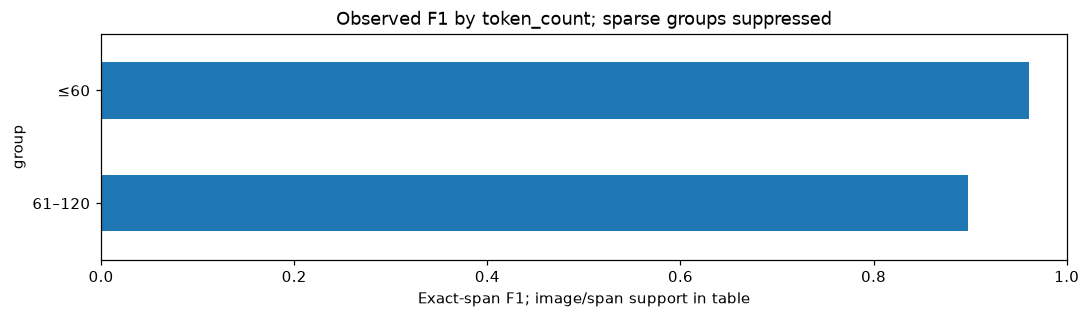

Grouping: aspect_ratio


,dimension,group,tp,pred_spans,gold_spans,parsed_predictions,pred_entities,token_errors,token_support,images,entity_contributing_images,sufficient_support,precision,recall,f1,parsing_success,note
0,aspect_ratio,landscape >1.5,104,118,113,91,118,21,746,11,11,True,0.881356,0.920354,0.900433,0.771186,Metrics suppressed below 5 distinct images or ...
1,aspect_ratio,near-square 0.75–1.5,70,70,70,63,70,0,565,6,6,True,1.000000,1.000000,1.000000,0.900000,Metrics suppressed below 5 distinct images or ...
2,aspect_ratio,portrait <0.75,27,29,28,25,29,1,240,3,3,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...


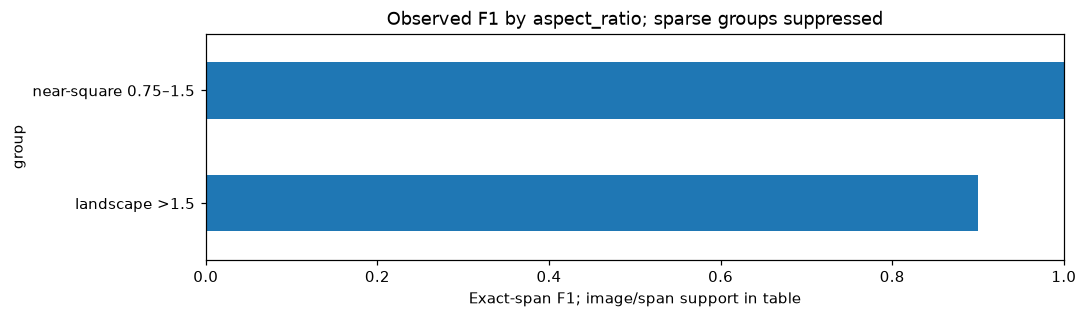

Grouping: width


,dimension,group,tp,pred_spans,gold_spans,parsed_predictions,pred_entities,token_errors,token_support,images,entity_contributing_images,sufficient_support,precision,recall,f1,parsing_success,note
0,width,1001–2000 px,75,87,84,68,87,17,649,6,6,True,0.862069,0.892857,0.877193,0.781609,Metrics suppressed below 5 distinct images or ...
1,width,>2000 px,36,38,36,30,38,4,299,3,3,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...
2,width,≤1000 px,90,92,91,81,92,1,603,11,11,True,0.978261,0.989011,0.983607,0.880435,Metrics suppressed below 5 distinct images or ...


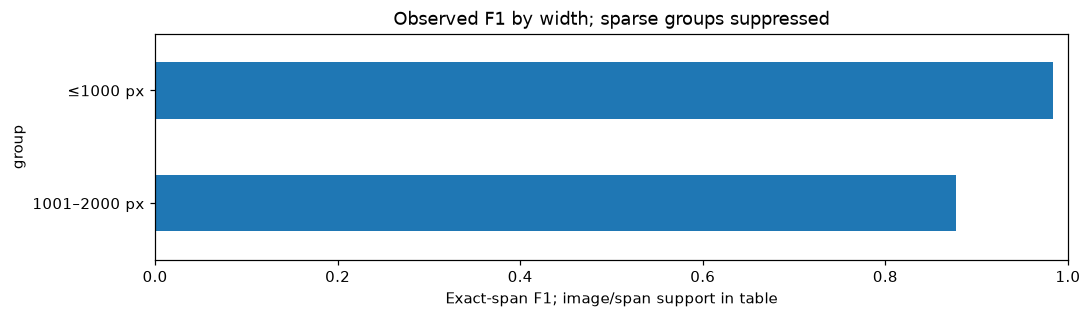

Grouping: metadata_fields_present


,dimension,group,tp,pred_spans,gold_spans,parsed_predictions,pred_entities,token_errors,token_support,images,entity_contributing_images,sufficient_support,precision,recall,f1,parsing_success,note
0,metadata_fields_present,0–3 metadata fields,166,182,176,148,182,22,1303,17,17,True,0.912088,0.943182,0.927374,0.813187,Metrics suppressed below 5 distinct images or ...
1,metadata_fields_present,4–5 metadata fields,35,35,35,31,35,0,248,3,3,False,NaN,NaN,NaN,NaN,Metrics suppressed below 5 distinct images or ...


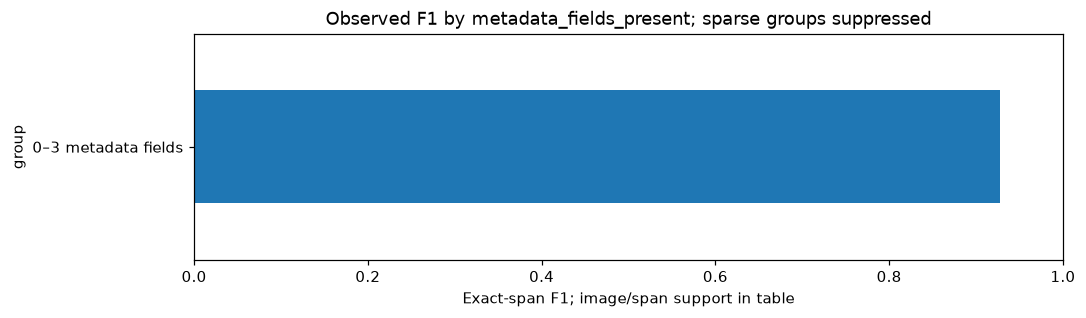

Grouping: structured_numeric


,dimension,group,tp,pred_spans,gold_spans,parsed_predictions,pred_entities,token_errors,token_support,images,entity_contributing_images,sufficient_support,precision,recall,f1,parsing_success,note
0,structured_numeric,numeric product metadata missing,12,13,12,11,13,2,1551,20,7,True,0.923077,1.000000,0.960000,0.846154,Metrics suppressed below 5 distinct images or ...
1,structured_numeric,numeric product metadata present,189,204,199,168,204,20,1551,20,20,True,0.926471,0.949749,0.937965,0.823529,Metrics suppressed below 5 distinct images or ...


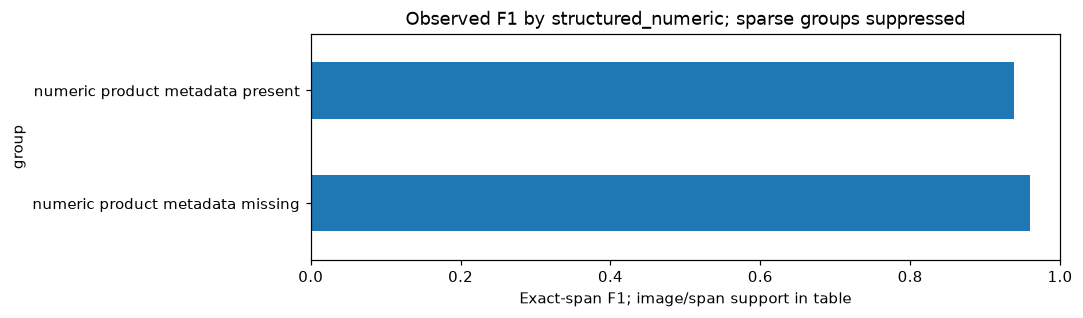

,barcode,image_path,token_index,ocr_token,gold_label,predicted_label,error_type,context,ocr_text_independently_verified,image_key
0,3760027470152,,80,"14,92",B-PROTEINS_100G,B-FAT_100G,wrong_entity_or_basis_label,"656 Kcal\n 2716 KJ\n 14,92 g\n 12,93 g\n 9...",False,test:6
1,3760027470152,,81,g\n,I-PROTEINS_100G,I-FAT_100G,wrong_entity_or_basis_label,"Kcal\n 2716 KJ\n 14,92 g\n 12,93 g\n 9,77 g\n",False,test:6
2,3760027470152,,82,"12,93",B-CARBOHYDRATES_100G,B-SATURATED_FAT_100G,wrong_entity_or_basis_label,"2716 KJ\n 14,92 g\n 12,93 g\n 9,77 g\n 57,74",False,test:6
3,3760027470152,,83,g\n,I-CARBOHYDRATES_100G,I-SATURATED_FAT_100G,wrong_entity_or_basis_label,"KJ\n 14,92 g\n 12,93 g\n 9,77 g\n 57,74 g\n",False,test:6
4,3760027470152,,84,"9,77",B-SUGARS_100G,B-CARBOHYDRATES_100G,wrong_entity_or_basis_label,"14,92 g\n 12,93 g\n 9,77 g\n 57,74 g\n 7,49",False,test:6
5,3760027470152,,85,g\n,I-SUGARS_100G,I-CARBOHYDRATES_100G,wrong_entity_or_basis_label,"g\n 12,93 g\n 9,77 g\n 57,74 g\n 7,49 g\n",False,test:6
6,3760027470152,,86,"57,74",B-FAT_100G,B-CARBOHYDRATES_100G,wrong_entity_or_basis_label,"12,93 g\n 9,77 g\n 57,74 g\n 7,49 g\n 8,23",False,test:6
7,3760027470152,,87,g\n,I-FAT_100G,I-CARBOHYDRATES_100G,wrong_entity_or_basis_label,"g\n 9,77 g\n 57,74 g\n 7,49 g\n 8,23 g\n",False,test:6
8,3760027470152,,88,"7,49",B-SATURATED_FAT_100G,B-SUGARS_100G,wrong_entity_or_basis_label,"9,77 g\n 57,74 g\n 7,49 g\n 8,23 g\n 1,80",False,test:6
9,3760027470152,,89,g\n,I-SATURATED_FAT_100G,I-SUGARS_100G,wrong_entity_or_basis_label,"g\n 57,74 g\n 7,49 g\n 8,23 g\n 1,80 g\n",False,test:6


No inferential causal claim is made from these small, selected, overlapping groups.


In [15]:
print('Overall cached count-based performance:', impact.metric_summary(tables['performance_rows']))
for dimension in ['nutrient', 'category', 'country', 'token_count', 'aspect_ratio', 'width', 'metadata_fields_present', 'structured_numeric']:
    grouped = impact.performance_groups(tables['performance_rows'], dimension)
    print('Grouping:', dimension)
    display(grouped)
    if not grouped.empty:
        supported = grouped.loc[grouped['sufficient_support']]
        if not supported.empty:
            supported.set_index('group')['f1'].plot.barh(figsize=(10, max(3, len(supported)*0.35)), xlim=(0, 1), title=f'Observed F1 by {dimension}; sparse groups suppressed')
            plt.xlabel('Exact-span F1; image/span support in table')
            save_plot(f'performance_{dimension}.png')
display(tables['error_examples'])
print('No inferential causal claim is made from these small, selected, overlapping groups.')

## 5. Cross-source consistency and five evidence-backed actions

Match only mapped nutrient identity, unit and `per_100g` field-name basis conventions. Mass units are converted to grams; energy kJ and kcal declarations stay distinct. Serving values, qualifiers (`<`), missing product fields and incompatible units are explicitly unscored. Agreement uses a predeclared **1% relative + 1e-8 absolute** numeric tolerance; this is a metadata-review threshold, not model accuracy.

A discrepancy does not prove which source is wrong. Product metadata may be edited or refer to different packaging. The five computed findings below distinguish observations from possible explanations and recommend review rather than correction or test-set tuning.

Comparison status counts: {'compatible_agreement': 107, 'not_comparable_basis_unit_qualifier_or_missing_metadata': 52, 'compatible_discrepancy': 20}
Compatible fields: 127 Discrepancies: 20


,image_key,barcode,split,country,category,width,height,token_count,aspect_ratio,metadata_fields_present,...,predicted_value,product_value,source_field,compatible,difference,within_one_percent,prediction_validation_flags,comparison_status,reference_is_gold,interpretation
0,test:6,3760027470152,test,France,None,2000,1125,110,1.777778,2,...,12.930,7.490000,saturated-fat_100g,True,5.440000,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...
2,test:6,3760027470152,test,France,None,2000,1125,110,1.777778,2,...,7.490,9.770000,sugars_100g,True,-2.280000,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...
3,test:6,3760027470152,test,France,None,2000,1125,110,1.777778,2,...,14.920,57.740000,fat_100g,True,-42.820000,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...
4,test:6,3760027470152,test,France,None,2000,1125,110,1.777778,2,...,2716.000,2675.670000,energy-kj_100g,True,40.330000,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...
48,test:23,8410573103169,test,en:es,None,1797,1200,135,1.497500,2,...,2166.000,2129.600000,energy-kj_100g,True,36.400000,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...
55,test:26,8433329104128,test,None,None,2050,940,75,2.180851,2,...,0.820,82.000000,fat_100g,True,-81.180000,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...
72,test:35,4056489232124,test,None,None,569,541,36,1.051756,3,...,779.000,765.800000,energy-kj_100g,True,13.200000,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...
80,test:55,3383810002646,test,en:fr,None,473,285,33,1.659649,2,...,165.000,183.399997,energy-kj_100g,True,-18.399997,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...
87,test:57,3661945710026,test,None,None,762,367,56,2.076294,2,...,1491.000,1465.400000,energy-kj_100g,True,25.600000,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...
94,test:59,6141437686062,test,en:es,None,782,351,27,2.227920,2,...,749.000,196.000000,energy-kj_100g,True,553.000000,False,,compatible_discrepancy,False,Field-name/basis/unit compatible only; current...


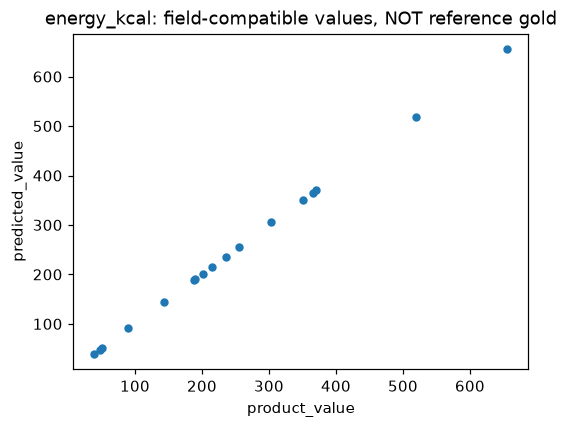

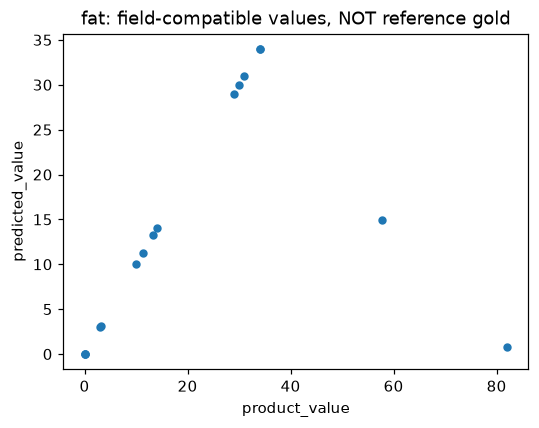

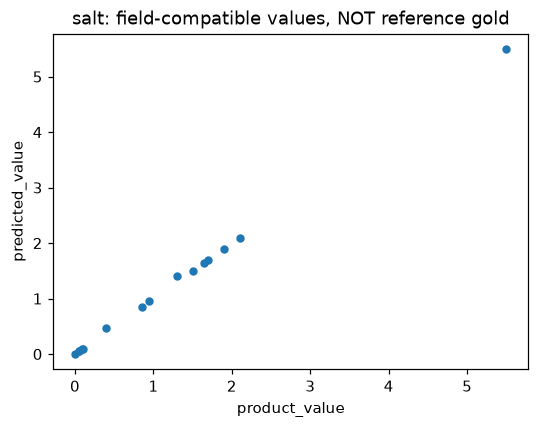

,EDA Finding,Impact on Part 2,Recommended Action,evidence_type,support
0,"Annotation selection: 3,075 matched products o...",Observed metadata-distribution difference demo...,Keep broad EDA and annotation-selected analysi...,observed descriptive association,"4,881,991 full rows; 3,075 matched products"
1,"1,313/26,115 image–nutrient pairs have a gold ...",Missing product metadata can coexist with anno...,Preserve gold annotations independently; label...,observed paired-source availability,"26,115 gold-positive image–nutrient pairs"
2,38/217 predicted BIO spans in the aligned cach...,High span tagging accuracy does not ensure com...,Report parsing support beside BIO PRF and keep...,observed cached-output diagnostic,20 evaluated images; 217 predicted spans
3,20/127 basis/unit/identity-compatible extracte...,Database records and extracted image values ar...,Prioritize discrepancy examples for image/vers...,observed cross-source discrepancy; causes unve...,127 comparable fields
4,Performance context is available for only 20/3...,Small or overlapping strata cannot establish r...,"Maintain the frozen official-test cohort, show...",observed sample limitation; driver claims expl...,20 official-test images; zero new inference runs


Saved Parquet/CSV artifacts: ['agreement_rows.parquet', 'anomaly_rows.parquet', 'anomaly_thresholds.parquet', 'coverage_rows.parquet', 'coverage_summary.parquet', 'distribution_bins.parquet', 'error_examples.parquet', 'figures', 'full_background_manifest.json', 'image_rows.parquet', 'key_findings.csv', 'label_distributions.parquet', 'manifest.json', 'metadata_coverage.parquet', 'performance_aspect_ratio.parquet', 'performance_category.parquet', 'performance_country.parquet', 'performance_metadata_fields_present.parquet', 'performance_nutrient.parquet', 'performance_rows.parquet', 'performance_structured_numeric.parquet', 'performance_token_count.parquet', 'performance_width.parquet', 'prediction_audit.json', 'representativeness.parquet']
Limitations: Observational audit; no causal claims.
Only the seeded cached official-test cohort is evaluated; train predictions are unavailable, not zero.
Full numeric quantiles approximate from seed42 bounded uniform reservoirs; matched/50K quantiles 

In [8]:
agreement = tables['agreement_rows']
comparable = agreement.loc[agreement['compatible']]
print('Comparison status counts:', agreement['comparison_status'].value_counts().to_dict())
print('Compatible fields:', len(comparable), 'Discrepancies:', int((~comparable['within_one_percent'].astype(bool)).sum()))
display(comparable.loc[~comparable['within_one_percent'].astype(bool)])
for nutrient in ['energy_kcal', 'fat', 'salt']:
    selected = comparable.loc[comparable['nutrient'].eq(nutrient)]
    if not selected.empty:
        selected.plot.scatter(x='product_value', y='predicted_value', figsize=(5, 4), title=f'{nutrient}: field-compatible values, NOT reference gold')
        save_plot(f'agreement_{nutrient}.png')
display(pd.DataFrame(findings).rename(columns={'eda_finding':'EDA Finding', 'impact':'Impact on Part 2', 'action':'Recommended Action'}))
print('Saved Parquet/CSV artifacts:', [path.name for path in sorted(OUTPUT.glob('*'))])
print('Limitations:', '\n'.join(manifest['limitations']))

## 6. Validation and reusable outputs

The new dashboard section loads only cached Parquet/CSV and aggregates filtered image–nutrient rows; it does not scan the complete gzip or run LayoutLM. Nutrient/country/category/split filters operate where linked rows support them; fixed full-background tables are explicitly labelled and support nutrient selection only. Sparse groups stay blank, not zero. The dashboard compares one nutrient/unit scale at a time for numeric agreement and validates linked input/prediction hashes before showing cached findings.

Validation checks integration counts, complete cached gold/token/box alignment, exact-span count consistency, original input hashes, conservative unit/basis rules, missing-versus-unmapped fields, denominator integrity, sparse-group suppression, and both new/old UI views. Full-source quantiles remain approximate and all causal/error-source explanations remain hypotheses.

In [22]:
import subprocess
for input_path, expected_hash in manifest['input_sha256'].items():
    assert impact.file_hash(input_path) == expected_hash, f'Protected input changed externally: {input_path}'
assert manifest['matched_products'] == provenance['summary']['overlapping_barcodes']
assert manifest['evaluated_images'] == tables['performance_rows']['image_key'].nunique()
assert set(tables['performance_rows']['split']) == {'test'}
assert manifest['model_inference_runs'] == 0
bundle = json.loads((ROOT / 'data/part2_cache/layoutlm_bio/latest_test_bundle.json').read_text(encoding='utf-8'))
measured = impact.metric_summary(tables['performance_rows'])
assert measured['tp'] == bundle['fine_grained_metrics']['true_positive_spans']
assert measured['gold_spans'] == bundle['fine_grained_metrics']['gold_spans']
assert measured['token_support'] == bundle['fine_grained_metrics']['token_support']
assert measured['token_errors'] == len(tables['error_examples'])
assert len(findings) == 5
print('Final cached metrics:', measured)
checks = subprocess.run([sys.executable, '-m', 'pytest', '-q', str(ROOT / 'tests')], cwd=ROOT, capture_output=True, text=True)
print(checks.stdout)
if checks.returncode:
    print(checks.stderr)
    raise RuntimeError('Regression tests failed.')
print('Validation passed; no inference, dataset download or existing notebook/gold edits were performed.')

Final cached metrics: {'tp': 201, 'pred_spans': 217, 'gold_spans': 211, 'parsed_predictions': 179, 'pred_entities': 217, 'token_errors': 22, 'token_support': 1551, 'images': 20, 'entity_contributing_images': 20, 'sufficient_support': True, 'precision': 0.9262672811059908, 'recall': 0.95260663507109, 'f1': 0.939252336448598, 'parsing_success': 0.8248847926267281, 'note': 'Metrics suppressed below 5 distinct images or 5 gold spans; parsing requires 5 predicted entities. All counts remain visible.'}
........................................................................ [ 87%]
..........                                                               [100%]
82 passed in 2.87s

Validation passed; no inference, dataset download or existing notebook/gold edits were performed.
